In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.functions import min as spark_min, max as spark_max
from pyspark.sql.functions import least, greatest,col
from functools import reduce
from operator import add

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [2]:
import sys
import pyspark
import subprocess

print("Python version:", sys.version)
print("PySpark version:", pyspark.__version__)

result = subprocess.run(
    ["java", "-version"],
    capture_output=True,
    text=True
)

print("\nJava version:")
print(result.stderr)

Python version: 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
PySpark version: 4.2.0

Java version:
java version "21.0.12" 2026-07-21 LTS
Java(TM) SE Runtime Environment (build 21.0.12+7-LTS-205)
Java HotSpot(TM) 64-Bit Server VM (build 21.0.12+7-LTS-205, mixed mode, sharing)



In [3]:
spark = SparkSession.builder \
    .appName("FashionMNIST_CNN_Classification") \
    .master("local[2]") \
    .getOrCreate()

print("Spark session created successfully!")
print("Spark version:", spark.version)

c:\Users\maduo\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark session created successfully!
Spark version: 4.2.0


In [4]:
train_path = r"C:\Users\maduo\Desktop\PDANA2\POE\fashion-mnist_train.csv"
test_path = r"C:\Users\maduo\Desktop\PDANA2\POE\fashion-mnist_test.csv"

train_pd = pd.read_csv(train_path)
test_pd = pd.read_csv(test_path)

# Convert Pandas DataFrames into Spark DataFrames

train_df = spark.createDataFrame(train_pd)
test_df = spark.createDataFrame(test_pd)

print("Training dataset loaded:", train_df.count())
print("Testing dataset loaded:", test_df.count())

c:\Users\maduo\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyspark\sql\pandas\conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\maduo\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyspark\sql\pandas\conversion.py:936: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\maduo\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyspark\sql\pandas\conversion.py:687: UserWarning: createDataFrame attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spar

Training dataset loaded: 60000
Testing dataset loaded: 10000


In [5]:
# Display dataset dimensions

print("Training dataset dimensions:", train_df.count(), "rows,", len(train_df.columns), "columns")
print("Testing dataset dimensions:", test_df.count(), "rows,", len(test_df.columns), "columns")

# Display schema

print("\nTraining dataset schema:")
train_df.printSchema()

Training dataset dimensions: 60000 rows, 785 columns
Testing dataset dimensions: 10000 rows, 785 columns

Training dataset schema:
root
 |-- label: long (nullable = true)
 |-- pixel1: long (nullable = true)
 |-- pixel2: long (nullable = true)
 |-- pixel3: long (nullable = true)
 |-- pixel4: long (nullable = true)
 |-- pixel5: long (nullable = true)
 |-- pixel6: long (nullable = true)
 |-- pixel7: long (nullable = true)
 |-- pixel8: long (nullable = true)
 |-- pixel9: long (nullable = true)
 |-- pixel10: long (nullable = true)
 |-- pixel11: long (nullable = true)
 |-- pixel12: long (nullable = true)
 |-- pixel13: long (nullable = true)
 |-- pixel14: long (nullable = true)
 |-- pixel15: long (nullable = true)
 |-- pixel16: long (nullable = true)
 |-- pixel17: long (nullable = true)
 |-- pixel18: long (nullable = true)
 |-- pixel19: long (nullable = true)
 |-- pixel20: long (nullable = true)
 |-- pixel21: long (nullable = true)
 |-- pixel22: long (nullable = true)
 |-- pixel23: long (null

In [6]:
# Display first five records

train_df.show(5, truncate=False)

+-----+------+------+------+------+------+------+------+------+------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+---

In [7]:
# Dataset dimensions

print("Training rows:", train_df.count())
print("Training columns:", len(train_df.columns))

print("Testing rows:", test_df.count())
print("Testing columns:", len(test_df.columns))

# Dataset schema

train_df.printSchema()

Training rows: 60000
Training columns: 785
Testing rows: 10000
Testing columns: 785
root
 |-- label: long (nullable = true)
 |-- pixel1: long (nullable = true)
 |-- pixel2: long (nullable = true)
 |-- pixel3: long (nullable = true)
 |-- pixel4: long (nullable = true)
 |-- pixel5: long (nullable = true)
 |-- pixel6: long (nullable = true)
 |-- pixel7: long (nullable = true)
 |-- pixel8: long (nullable = true)
 |-- pixel9: long (nullable = true)
 |-- pixel10: long (nullable = true)
 |-- pixel11: long (nullable = true)
 |-- pixel12: long (nullable = true)
 |-- pixel13: long (nullable = true)
 |-- pixel14: long (nullable = true)
 |-- pixel15: long (nullable = true)
 |-- pixel16: long (nullable = true)
 |-- pixel17: long (nullable = true)
 |-- pixel18: long (nullable = true)
 |-- pixel19: long (nullable = true)
 |-- pixel20: long (nullable = true)
 |-- pixel21: long (nullable = true)
 |-- pixel22: long (nullable = true)
 |-- pixel23: long (nullable = true)
 |-- pixel24: long (nullable = tru

In [8]:
# Count observations per clothing category

class_distribution = train_df.groupBy("label") \
    .count() \
    .orderBy("label")

class_distribution.show()

+-----+-----+
|label|count|
+-----+-----+
|    0| 6000|
|    1| 6000|
|    2| 6000|
|    3| 6000|
|    4| 6000|
|    5| 6000|
|    6| 6000|
|    7| 6000|
|    8| 6000|
|    9| 6000|
+-----+-----+



There are 10 different clothing categories and each category has 6000 images and the training dataset has 60 000 images in total. The classes are balanced and no category is overrepresented or underrepresented.

In [9]:
from pyspark.sql.functions import col, sum as spark_sum, when

missing_values = train_df.select([
    spark_sum(
        when(col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in train_df.columns
])

missing_values.show()

+-----+------+------+------+------+------+------+------+------+------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+---

In [10]:
from pyspark.sql.functions import min as spark_min, max as spark_max

pixel_columns = train_df.columns[1:]

pixel_range = train_df.select(
    spark_min(
        least(*[col(c) for c in pixel_columns])
    ).alias("Minimum Pixel Value"),

    spark_max(
        greatest(*[col(c) for c in pixel_columns])
    ).alias("Maximum Pixel Value")
)

pixel_range.show()

+-------------------+-------------------+
|Minimum Pixel Value|Maximum Pixel Value|
+-------------------+-------------------+
|                  0|                255|
+-------------------+-------------------+



Visualize sample images

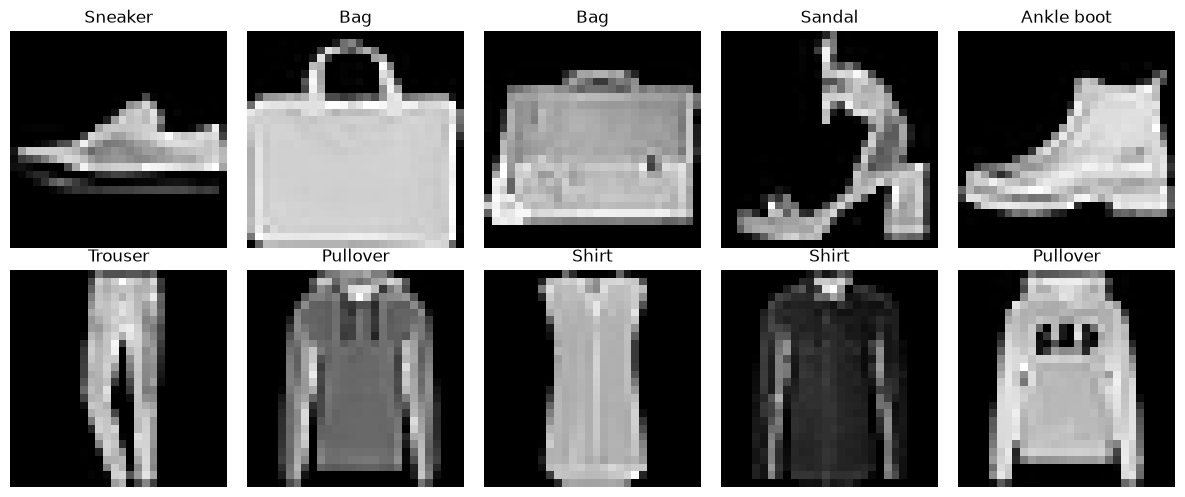

In [11]:
# Select 10 sample images
sample_images = train_pd.sample(10, random_state=42)

# Define clothing categories
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker",
    "Bag", "Ankle boot"
]

# Create a figure
plt.figure(figsize=(12, 5))

for i, (_, row) in enumerate(sample_images.iterrows()):

    # Extract label
    label = int(row["label"])

    # Extract pixel values
    image = row.drop("label").values.reshape(28, 28)

    # Display image
    plt.subplot(2, 5, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

Each image is relatively small, with a resolution of 28 x 28 pixels. Meaning the clothing items have limited visual detail.

The images use different shades of grey to represent clothing shapes and textures.

Shoes,bags and trousers have more distinguishable shapes compared to other clothing categories.

In [13]:
# Select all pixel columns (exclude label)
pixel_data = train_pd.iloc[:, 1:].values

# Calculate average pixel intensity for each image
average_intensity = pixel_data.mean(axis=1)

# Display descriptive statistics
pd.Series(average_intensity).describe()

count    60000.000000
mean        72.956831
std         32.081512
min          4.943878
25%         47.455357
50%         69.403699
75%         97.403061
max        191.820153
dtype: float64

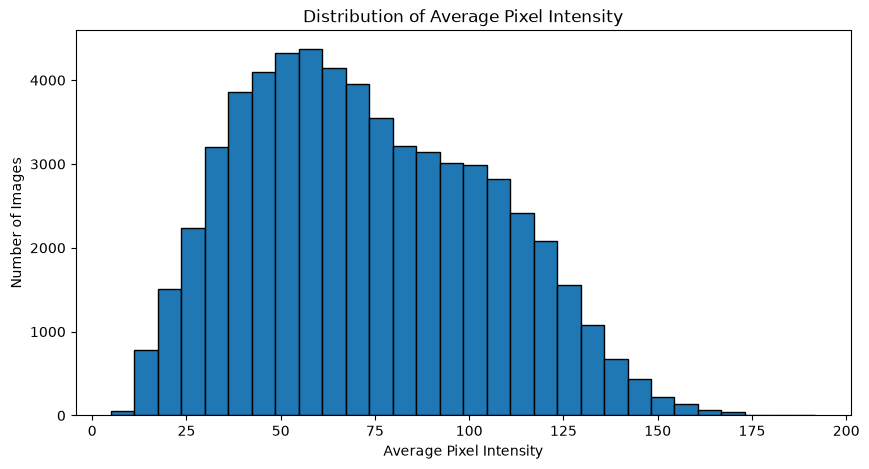

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(
    average_intensity,
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Average Pixel Intensity")
plt.xlabel("Average Pixel Intensity")
plt.ylabel("Number of Images")

plt.show()

In [15]:
# Check missing values
missing_values = train_pd.isnull().sum()

print("Total missing values:", missing_values.sum())

# Check duplicate records
duplicate_count = train_pd.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total missing values: 0
Total duplicate records: 43


Investigate the duplicate records

In [16]:
# Extract all duplicated records, including original occurrences
duplicates = train_pd[
    train_pd.duplicated(keep=False)
]

print("Total records involved in duplicates:", len(duplicates))

print("\nDuplicate records by category:")
print(duplicates["label"].value_counts().sort_index())

Total records involved in duplicates: 86

Duplicate records by category:
label
0     4
1     8
2    24
3     6
4    10
6    22
7     8
9     4
Name: count, dtype: int64


In [17]:
pixel_columns = train_pd.columns[1:].tolist()

label_conflicts = (
    train_pd.groupby(pixel_columns)["label"]
    .nunique()
)

print(
    "Identical images with different labels:",
    (label_conflicts > 1).sum()
)

Identical images with different labels: 0


Checking the possible overlap between training and testing datset

In [18]:
# Extract pixel columns
pixel_columns = train_pd.columns[1:].tolist()

# Generate hashes for each image
train_hashes = pd.util.hash_pandas_object(
    train_pd[pixel_columns],
    index=False
)

test_hashes = pd.util.hash_pandas_object(
    test_pd[pixel_columns],
    index=False
)

# Check whether test images appear in training data
train_hash_set = set(train_hashes)

overlap_count = test_hashes.isin(train_hash_set).sum()

print("Test images also found in training data:", overlap_count)

Test images also found in training data: 10


In [19]:
import numpy as np

# Map training image hashes to their row positions
train_hash_map = {}

for idx, h in train_hashes.items():
    train_hash_map.setdefault(h, []).append(idx)

exact_matches = []

# Compare matching hashes using actual pixel values
for test_idx, h in test_hashes.items():

    if h in train_hash_map:

        test_image = test_pd.loc[test_idx, pixel_columns].values

        for train_idx in train_hash_map[h]:

            train_image = train_pd.loc[train_idx, pixel_columns].values

            if np.array_equal(test_image, train_image):
                exact_matches.append((train_idx, test_idx))

print("Exact matching images:", len(exact_matches))

Exact matching images: 10


In [20]:
# Create a report of matching images
overlap_report = pd.DataFrame(
    exact_matches,
    columns=["train_index", "test_index"]
)

# Retrieve labels from both datasets
overlap_report["train_label"] = [
    train_pd.loc[i, "label"]
    for i in overlap_report["train_index"]
]

overlap_report["test_label"] = [
    test_pd.loc[i, "label"]
    for i in overlap_report["test_index"]
]

# Check whether labels agree
overlap_report["labels_match"] = (
    overlap_report["train_label"] ==
    overlap_report["test_label"]
)

print(overlap_report)

   train_index  test_index  train_label  test_label  labels_match
0        12404        4037            6           6          True
1        34617        4990            2           2          True
2        48228        5867            3           3          True
3        15943        6659            1           1          True
4        35772        7216            3           3          True
5         3763        7243            1           1          True
6        22403        7762            3           3          True
7         4944        7781            4           4          True
8         6168        9227            3           3          True
9        52205        9560            6           0         False


In [21]:
# Identify test indices involved in exact matches
overlapping_test_indices = [
    test_idx for train_idx, test_idx in exact_matches
]

# Remove overlapping records from test dataset
test_clean_pd = test_pd.drop(
    index=overlapping_test_indices
).reset_index(drop=True)

print("Original test dataset:", len(test_pd))
print("Cleaned test dataset:", len(test_clean_pd))
print(
    "Removed overlapping images:",
    len(test_pd) - len(test_clean_pd)
)

Original test dataset: 10000
Cleaned test dataset: 9990
Removed overlapping images: 10


Separate features and labels

In [22]:
# Separate training features and labels
X_train = train_pd.drop("label", axis=1).values
y_train = train_pd["label"].values

# Separate testing features and labels
X_test = test_clean_pd.drop("label", axis=1).values
y_test = test_clean_pd["label"].values

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

Training features: (60000, 784)
Training labels: (60000,)
Testing features: (9990, 784)
Testing labels: (9990,)


In [23]:
# Convert pixel values to a range of 0 to 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training pixel range:", X_train.min(), "to", X_train.max())
print("Testing pixel range:", X_test.min(), "to", X_test.max())

Training pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0


In [24]:
# Reshape training and testing images
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training image shape:", X_train.shape)
print("Testing image shape:", X_test.shape)

Training image shape: (60000, 28, 28, 1)
Testing image shape: (9990, 28, 28, 1)


Data splitting

In [25]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training images: (48000, 28, 28, 1)
Validation images: (12000, 28, 28, 1)
Training labels: (48000,)
Validation labels: (12000,)


In [26]:
print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

Training class distribution:
0    4800
1    4800
2    4800
3    4800
4    4800
5    4800
6    4800
7    4800
8    4800
9    4800
Name: count, dtype: int64

Validation class distribution:
0    1200
1    1200
2    1200
3    1200
4    1200
5    1200
6    1200
7    1200
8    1200
9    1200
Name: count, dtype: int64


In [29]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


BUILD THE CNN MODEL

In [30]:

model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

In [31]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Train the CNN

In [33]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping]
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.7923 - loss: 0.5767 - val_accuracy: 0.8587 - val_loss: 0.3776
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.8609 - loss: 0.3816 - val_accuracy: 0.8859 - val_loss: 0.3157
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.8791 - loss: 0.3309 - val_accuracy: 0.8827 - val_loss: 0.3122
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.8906 - loss: 0.2984 - val_accuracy: 0.8991 - val_loss: 0.2768
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.8982 - loss: 0.2749 - val_accuracy: 0.8998 - val_loss: 0.2710
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.9076 - loss: 0.2512 - val_accuracy: 0.9072 - val_loss: 0.2554
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - accuracy: 0.9132 - loss: 0.2332 - val_accuracy: 0.9018 - val_loss: 0.2550
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.9189 - loss: 0.2189 - 

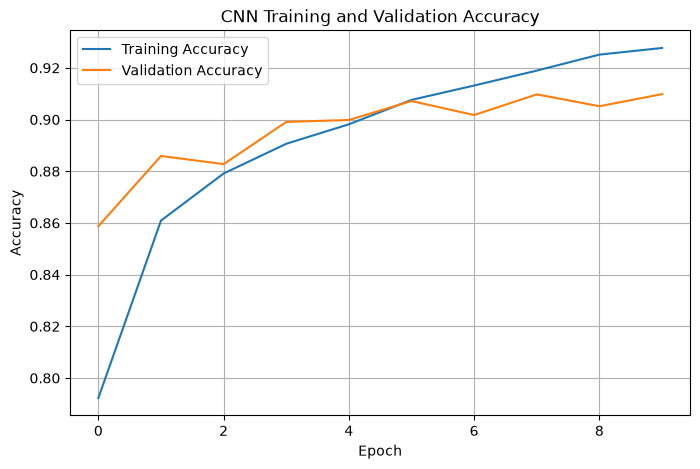

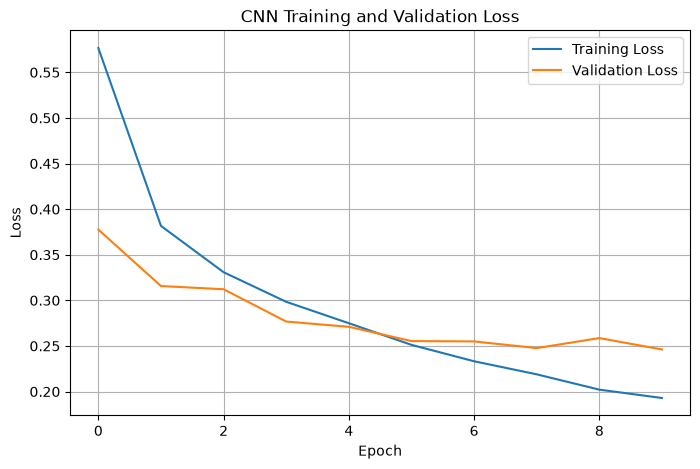

In [34]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Evaluate the model on the test dataset

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9143 - loss: 0.2323


ConnectionRefusedError: [WinError 10061] No connection could be made because the target machine actively refused it

In [36]:
import builtins

print("Test Accuracy:", builtins.round(test_accuracy * 100, 2), "%")
print("Test Loss:", builtins.round(test_loss, 4))

Test Accuracy: 91.43 %
Test Loss: 0.2323


Generate predictions

In [37]:
y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Predictions generated successfully!
Number of predictions: 9990


Generate the classification report

In [38]:
from sklearn.metrics import classification_report

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.86      0.85       999
     Trouser       0.99      0.98      0.99       998
    Pullover       0.84      0.90      0.87       999
       Dress       0.90      0.94      0.92       996
        Coat       0.89      0.84      0.87       999
      Sandal       0.98      0.99      0.98      1000
       Shirt       0.78      0.73      0.75       999
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.95      0.96      1000

    accuracy                           0.91      9990
   macro avg       0.91      0.91      0.91      9990
weighted avg       0.91      0.91      0.91      9990



Generate the Confusion matrix

<Figure size 1000x800 with 0 Axes>

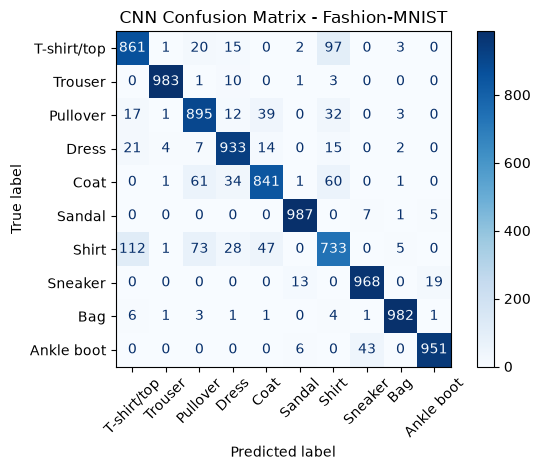

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("CNN Confusion Matrix - Fashion-MNIST")
plt.tight_layout()
plt.show()

In [41]:
import pandas as pd
import numpy as np

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

# Remove correct predictions on the diagonal
np.fill_diagonal(cm, 0)

# Find the five largest misclassification counts
confusion_pairs = []

for i in range(len(class_names)):
    for j in range(len(class_names)):
        if cm[i, j] > 0:
            confusion_pairs.append({
                "Actual Category": class_names[i],
                "Predicted Category": class_names[j],
                "Misclassified Images": cm[i, j]
            })

confusion_pairs_df = pd.DataFrame(confusion_pairs)

confusion_pairs_df = confusion_pairs_df.sort_values(
    by="Misclassified Images",
    ascending=False
)

confusion_pairs_df.head(5)

,Actual Category,Predicted Category,Misclassified Images
31,Shirt,T-shirt/top,112
4,T-shirt/top,Shirt,97
33,Shirt,Pullover,73
23,Coat,Pullover,61
26,Coat,Shirt,60
